CSV file created successfully!

========== ORIGINAL DATA ==========
      Name  Age  Subject1  Subject2  Subject3  Subject4  Percentage
0   Muskan   20        85        80        88        82       83.75
1    Priya   19        90        92        89        94       91.25
2    Rahul   21        78        75        80        77       77.50
3     Aman   20        67        70        65        72       68.50
4     Neha   19        88        85        90        87       87.50
5     Riya   20        75        78        76        80       77.25
6    Karan   21        82        84        85        83       83.50
7   Anjali   19        95        94        96        93       94.50
8    Rohit   20        70        72        74        71       71.75
9    Pooja   21        86        88        87        89       87.50
10  Simran   19        91        90        92        89       90.50
11   Arjun   20        73        76        78        75       75.50
12  Kavita   21        84        86        83   

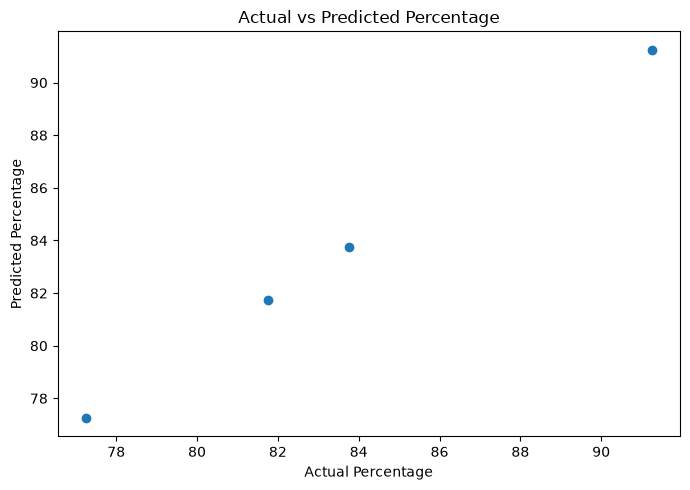


========== ACTUAL VS PREDICTED ==========
 Actual  Predicted
  83.75      83.75
  81.75      81.75
  77.25      77.25
  91.25      91.25

Prediction results saved to prediction_results.csv

PROJECT COMPLETED SUCCESSFULLY!


In [2]:
# ==========================================================
# STUDENT MARKS PREDICTION - MACHINE LEARNING PROJECT
# ==========================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error


# ==========================================================
# 1. CREATE DATASET
# ==========================================================

file_name = "students.csv"

data = {
    "Name": [
        "Muskan", "Priya", "Rahul", "Aman", "Neha",
        "Riya", "Karan", "Anjali", "Rohit", "Pooja",
        "Simran", "Arjun", "Kavita", "Mohit", "Sneha",
        "Vikas", "Nisha", "Deepak", "Payal", "Varun"
    ],

    "Age": [
        20, 19, 21, 20, 19,
        20, 21, 19, 20, 21,
        19, 20, 21, 19, 20,
        21, 19, 20, 21, 20
    ],

    "Subject1": [
        85, 90, 78, 67, 88,
        75, 82, 95, 70, 86,
        91, 73, 84, 68, 89,
        77, 92, 80, 87, 76
    ],

    "Subject2": [
        80, 92, 75, 70, 85,
        78, 84, 94, 72, 88,
        90, 76, 86, 65, 91,
        79, 93, 81, 89, 74
    ],

    "Subject3": [
        88, 89, 80, 65, 90,
        76, 85, 96, 74, 87,
        92, 78, 83, 69, 88,
        75, 94, 82, 86, 77
    ],

    "Subject4": [
        82, 94, 77, 72, 87,
        80, 83, 93, 71, 89,
        89, 75, 85, 67, 90,
        78, 95, 84, 88, 73
    ]
}

df = pd.DataFrame(data)

# Calculate percentage from four subjects
df["Percentage"] = (
    df[["Subject1", "Subject2", "Subject3", "Subject4"]]
    .mean(axis=1)
)

# Save dataset
df.to_csv(file_name, index=False)

print("CSV file created successfully!")


# ==========================================================
# 2. LOAD DATA
# ==========================================================

df = pd.read_csv(file_name)

print("\n========== ORIGINAL DATA ==========")
print(df)


# ==========================================================
# 3. CHECK DATA
# ==========================================================

print("\n========== DATA INFO ==========")
df.info()

print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())


# ==========================================================
# 4. REMOVE DUPLICATES
# ==========================================================

df = df.drop_duplicates().copy()

print("\n========== AFTER REMOVING DUPLICATES ==========")
print(df)


# ==========================================================
# 5. SELECT FEATURES AND TARGET
# ==========================================================

features = ["Subject1", "Subject2", "Subject3", "Subject4"]

X = df[features].copy()
y = df["Percentage"].copy()


# ==========================================================
# 6. HANDLE MISSING VALUES
# ==========================================================

X = X.fillna(X.mean())
y = y.fillna(y.mean())


# ==========================================================
# 7. TRAIN-TEST SPLIT
# ==========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\n========== TRAIN TEST SPLIT ==========")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


# ==========================================================
# 8. CREATE AND TRAIN MODEL
# ==========================================================

model = LinearRegression()

model.fit(X_train, y_train)

print("\nModel trained successfully!")


# ==========================================================
# 9. PREDICT TEST DATA
# ==========================================================

y_pred = model.predict(X_test)

print("\n========== PREDICTIONS ==========")
print("Actual Percentage:")
print(y_test.to_numpy())

print("\nPredicted Percentage:")
print(y_pred)


# ==========================================================
# 10. MODEL EVALUATION
# ==========================================================

mae = mean_absolute_error(y_test, y_pred)

print("\n========== MODEL EVALUATION ==========")
print("MAE:", round(mae, 2))

if len(y_test) >= 2:
    r2 = r2_score(y_test, y_pred)
    print("R2 Score:", round(r2, 4))
else:
    print("R2 Score cannot be calculated with fewer than 2 test samples.")


# ==========================================================
# 11. MODEL COEFFICIENTS
# ==========================================================

print("\n========== MODEL COEFFICIENTS ==========")

for subject, coefficient in zip(X.columns, model.coef_):
    print(subject, ":", round(coefficient, 4))

print("Intercept:", round(model.intercept_, 4))


# ==========================================================
# 12. PREDICT NEW STUDENT
# ==========================================================

new_student = pd.DataFrame(
    [[80, 85, 75, 90]],
    columns=features
)

predicted_percentage = model.predict(new_student)[0]

print("\n========== NEW STUDENT PREDICTION ==========")
print("Subject Marks:", new_student.iloc[0].to_dict())
print("Predicted Percentage:", round(predicted_percentage, 2), "%")


# ==========================================================
# 13. VISUALIZATION
# ==========================================================

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Percentage")
plt.ylabel("Predicted Percentage")
plt.title("Actual vs Predicted Percentage")

plt.tight_layout()
plt.show()


# ==========================================================
# 14. ACTUAL VS PREDICTED TABLE
# ==========================================================

result = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

print("\n========== ACTUAL VS PREDICTED ==========")
print(result.round(2).to_string(index=False))


# ==========================================================
# 15. SAVE PREDICTIONS
# ==========================================================

result.to_csv("prediction_results.csv", index=False)

print("\nPrediction results saved to prediction_results.csv")
print("\nPROJECT COMPLETED SUCCESSFULLY!")
